# 05.3 – Affordability matrix (SQ4), ANOVA and correlations

**Owner:** Luca · **Extra points:** ANOVA and correlation analysis, each with a p-value

This notebook uses the SQLite database `db/sci_alpi.db` (built by `05_sqlite_database.ipynb`) and answers three questions with the data that is already reliable:

1. **SQ4 – affordability:** how many hours of net work does a day pass cost, for a skier from each country in each destination country (a 4 × 4 matrix)?
2. **ANOVA:** do day-pass prices differ between Switzerland, Austria, Italy and France?
3. **Correlation:** which resort features go together with the day-pass price?

**Not in this notebook yet:** the chi-squared test of closed facilities against snow-risk classes (SQ5) and the ANOVA of snow loss by country and elevation. Both need a snow-risk class for all resorts, and the group has not agreed on a valid snow indicator yet (see `docs/snow_expansion_status.md`). They will be added when that table exists.

In [1]:
import sqlite3
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from statsmodels.stats.oneway import anova_oneway

ROOT = Path.cwd()
while not (ROOT / "requirements.txt").exists():
    ROOT = ROOT.parent
DB_PATH = ROOT / "db" / "sci_alpi.db"
FIG_DIR = ROOT / "docs" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
assert DB_PATH.exists(), "Run notebook 05_sqlite_database.ipynb first (it creates db/sci_alpi.db)."

con = sqlite3.connect(f"file:{DB_PATH}?mode=ro", uri=True)    # read-only: this notebook only reads
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

def sql(query, params=()):
    return pd.read_sql_query(query, con, params=params)

# Chart style: one blue for the data, grey text, no frame
BLUE_LIGHT, BLUE_MID, BLUE_DARK = "#cde2fb", "#3987e5", "#0d366b"
INK, INK_SOFT, GRID = "#0b0b0b", "#52514e", "#e3e2de"
plt.rcParams.update({"font.size": 11, "axes.edgecolor": GRID, "axes.labelcolor": INK_SOFT,
                     "xtick.color": INK_SOFT, "ytick.color": INK_SOFT, "text.color": INK,
                     "axes.spines.top": False, "axes.spines.right": False})
print("Database:", DB_PATH.relative_to(ROOT))

Database: db/sci_alpi.db


## 1. SQ4 – hours of net work for one day pass

For a skier from country *A* who skis in country *B*: `average day-pass price in B (EUR) / net hourly earnings in A (EUR)`. The price in the destination country is already in euros. The earnings come from the view `v_latest_earnings` (latest year with data: 2023 for CH, 2025 for AT, FR and IT). `CROSS JOIN` pairs every origin with every destination, which gives the 16 cells of the matrix.

The diagonal (origin = destination) is the result of notebook 05: a person who skis in their own country.

In [2]:
q_matrix = sql('''
    WITH dest AS (
        SELECT country AS destination,
               COUNT(*)           AS n_resorts,
               AVG(price_day_eur) AS avg_price_eur
        FROM resorts
        WHERE price_day_eur IS NOT NULL
        GROUP BY country
    )
    SELECT o.country                                   AS origin,
           d.destination,
           o.year                                      AS earnings_year,
           ROUND(o.net_earnings_hour_eur, 2)           AS net_hourly_eur,
           d.n_resorts,
           ROUND(d.avg_price_eur, 2)                   AS avg_price_eur,
           d.avg_price_eur / o.net_earnings_hour_eur   AS work_hours
    FROM v_latest_earnings o
    CROSS JOIN dest d
    ORDER BY o.country, d.destination
''')
matrix = q_matrix.pivot(index="origin", columns="destination", values="work_hours")
order = ["CH", "AT", "FR", "IT"]
matrix = matrix.loc[order, order]
matrix.round(2)

destination,CH,AT,FR,IT
origin,,,,
CH,1.57,1.56,1.07,1.32
AT,3.04,3.02,2.06,2.56
FR,3.98,3.95,2.70,3.35
IT,4.64,4.60,3.15,3.90


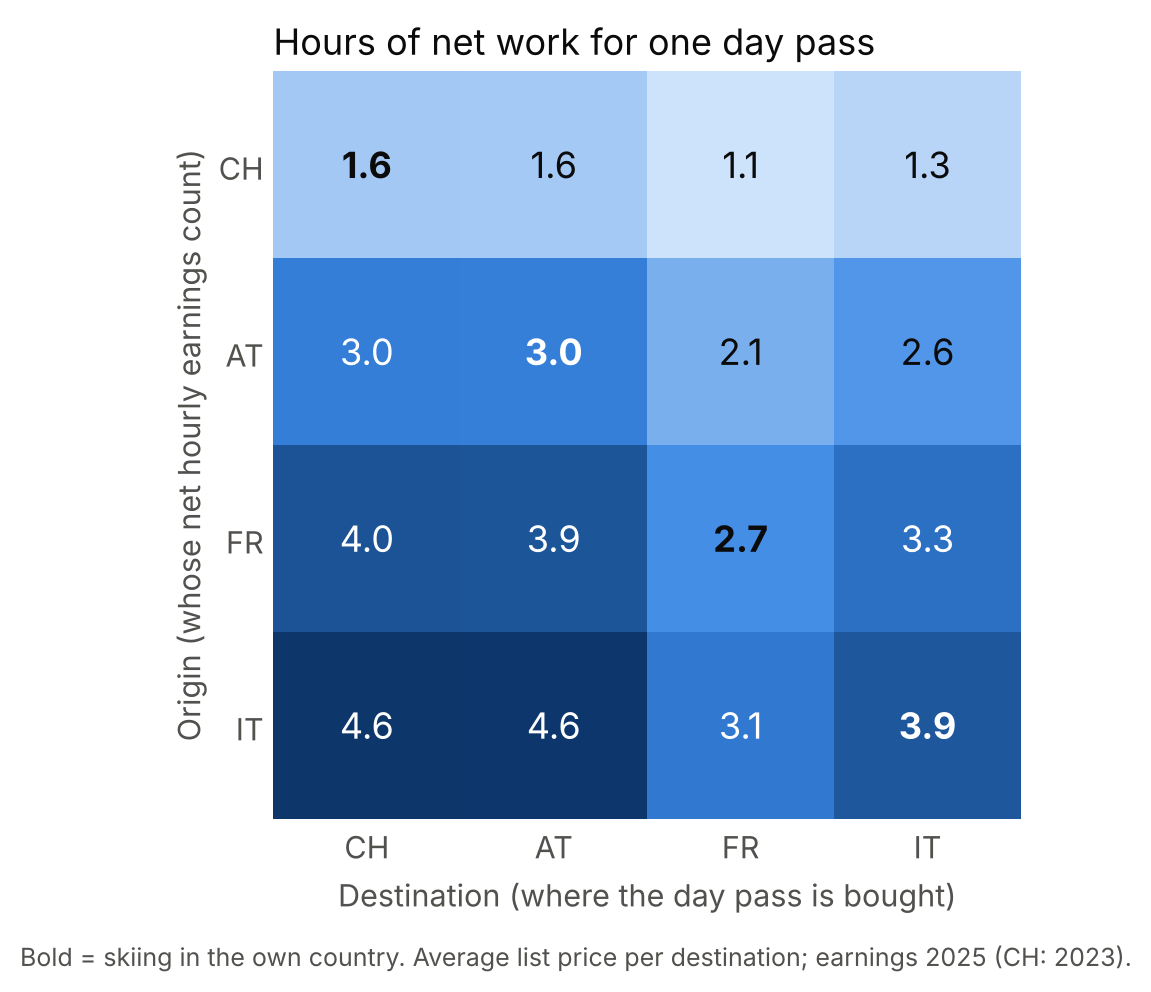

In [3]:
fig, ax = plt.subplots(figsize=(6.4, 4.8))
im = ax.imshow(matrix.values, cmap=plt.matplotlib.colors.LinearSegmentedColormap.from_list("blue", [BLUE_LIGHT, BLUE_MID, BLUE_DARK]))
ax.set_xticks(range(4), labels=order)
ax.set_yticks(range(4), labels=order)
ax.set_xlabel("Destination (where the day pass is bought)")
ax.set_ylabel("Origin (whose net hourly earnings count)")
for i in range(4):
    for j in range(4):
        v = matrix.values[i, j]
        ax.text(j, i, f"{v:.1f}", ha="center", va="center", fontsize=13,
                color="white" if v > matrix.values.mean() else INK, fontweight="bold" if i == j else "normal")
for spine in ax.spines.values():
    spine.set_visible(False)
ax.tick_params(length=0)
ax.set_title("Hours of net work for one day pass", loc="left", fontsize=13, color=INK)
fig.text(0.01, -0.02, "Bold = skiing in the own country. Average list price per destination; earnings 2025 (CH: 2023).",
         fontsize=9, color=INK_SOFT)
fig.tight_layout()
fig.savefig(FIG_DIR / "sq4_work_hours_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

**Reading the matrix.** A skier from Italy needs about 4.6 hours of net work for a day pass in Switzerland or Austria, 3.9 hours in Italy and 3.1 hours in France. A Swiss skier needs between 1.1 and 1.6 hours in every country. An Italian skiing in Switzerland therefore works about 0.7 hours (18 %) longer than at home. In every row France is the cheapest destination. The origin matters more than the destination: net hourly earnings in Switzerland are about three times those in Italy (46.6 against 15.8 EUR), while the dearest destination is only about 1.5 times as expensive as the cheapest (73.2 against 49.7 EUR).

Limits: earnings are nominal euros, without a correction for price levels (the PLI is in `country_stats` and could be used later); the Swiss earnings are from 2023, the others from 2025; the price is the list price of one day pass, not the real spending of a skier. The median-price check differs by at most 0.23 hours per cell, so the picture does not depend on a few very expensive resorts.

**Sensitivity check.** The matrix uses the mean price. With the median price the picture should not change; if it did, a few very expensive resorts would drive the result.

In [4]:
prices = sql("SELECT country, price_day_eur FROM resorts WHERE price_day_eur IS NOT NULL")
median_price = prices.groupby("country")["price_day_eur"].median()
earn = sql("SELECT country, net_earnings_hour_eur FROM v_latest_earnings").set_index("country")["net_earnings_hour_eur"]
matrix_median = pd.DataFrame({dest: median_price[dest] / earn for dest in order}).loc[order, order]
print("Mean-price matrix minus median-price matrix (hours):")
(matrix - matrix_median).round(2)

Mean-price matrix minus median-price matrix (hours):


destination,CH,AT,FR,IT
origin,,,,
CH,0.05,-0.01,0.08,0.03
AT,0.10,-0.02,0.15,0.06
FR,0.13,-0.02,0.20,0.08
IT,0.15,-0.03,0.23,0.10


## 2. ANOVA – do day-pass prices differ between countries?

**Question:** is the average day-pass price (EUR) the same in CH, AT, IT and FR?
**H0:** all four country means are equal. **H1:** at least one differs. Significance level 5 %.

The data are the 300 scraped price rows (see the notes in notebook 05: seven resort IDs appear twice, because the price differs by country or the row is repeated). The rows are treated as separate price observations.

In [5]:
d = sql("SELECT country, price_day_eur FROM resorts WHERE price_day_eur IS NOT NULL")
groups = {c: g["price_day_eur"].to_numpy() for c, g in d.groupby("country")}
desc = d.groupby("country")["price_day_eur"].agg(n="count", mean="mean", median="median", sd="std", min="min", max="max").round(1)
desc

,n,mean,median,sd,min,max
country,,,,,,
AT,76,72.6,73.0,8.2,47.0,86.5
CH,76,73.2,70.9,15.4,41.0,121.8
FR,73,49.7,46.0,13.0,26.0,84.2
IT,75,61.5,60.0,15.5,24.0,116.0


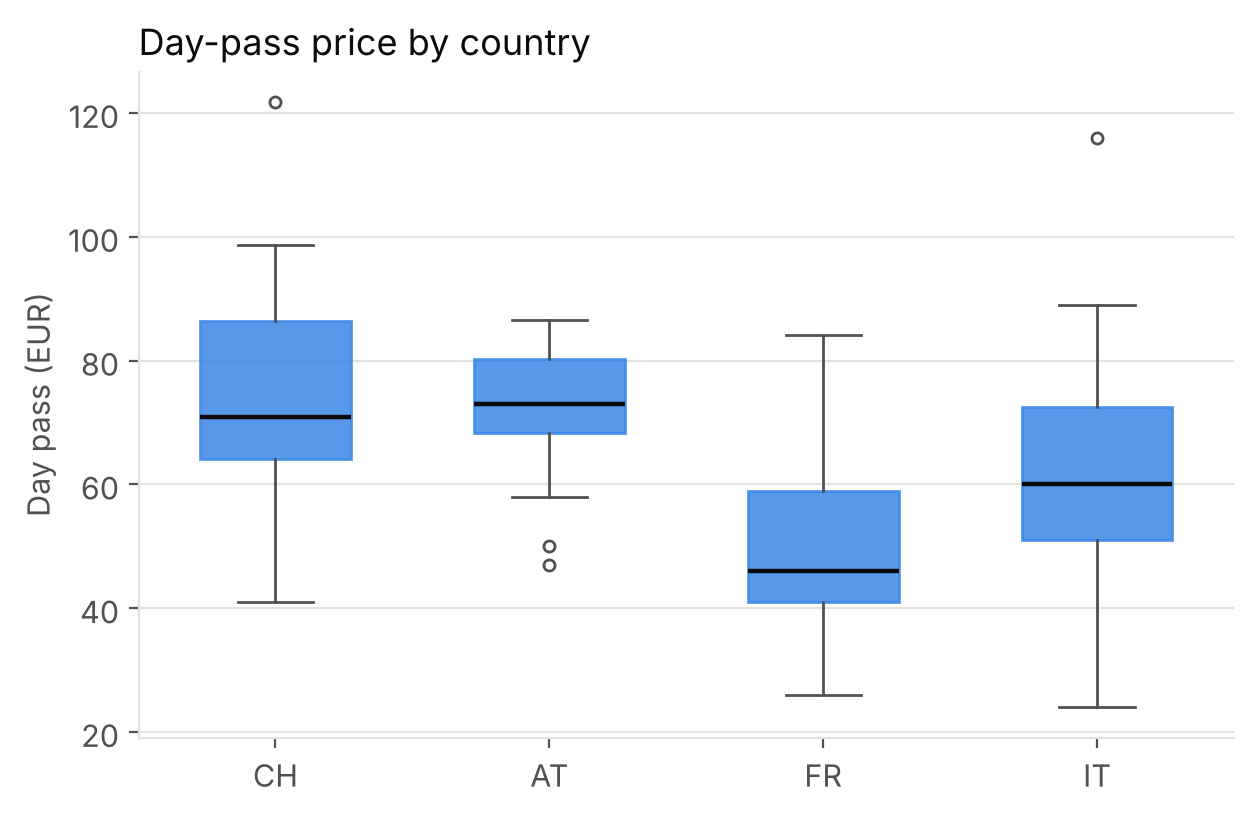

In [6]:
fig, ax = plt.subplots(figsize=(6.4, 4.2))
bp = ax.boxplot([groups[c] for c in order], tick_labels=order, patch_artist=True, widths=0.55,
                medianprops=dict(color=INK, linewidth=1.6), whiskerprops=dict(color=INK_SOFT), capprops=dict(color=INK_SOFT),
                flierprops=dict(marker="o", markersize=4, markerfacecolor="none", markeredgecolor=INK_SOFT))
for box in bp["boxes"]:
    box.set(facecolor=BLUE_MID, edgecolor=BLUE_MID, alpha=0.85)
ax.set_ylabel("Day pass (EUR)")
ax.yaxis.grid(True, color=GRID)
ax.set_axisbelow(True)
ax.set_title("Day-pass price by country", loc="left", fontsize=13, color=INK)
fig.tight_layout()
fig.savefig(FIG_DIR / "price_by_country_boxplot.png", dpi=150, bbox_inches="tight")
plt.show()

### Assumptions

One-way ANOVA assumes independent observations, roughly normal residuals and equal variances. Levene's test checks the equal variances. If it rejects, the Welch version of ANOVA (which does not need equal variances) and the rank-based Kruskal–Wallis test are the safer choice.

In [7]:
levene_stat, levene_p = stats.levene(*groups.values())
print(f"Levene test for equal variances: statistic = {levene_stat:.2f}, p = {levene_p:.5f}")

Levene test for equal variances: statistic = 7.38, p = 0.00009


In [8]:
# Classical ANOVA, Welch ANOVA and Kruskal-Wallis on the same data
F, p_classic = stats.f_oneway(*groups.values())
welch = anova_oneway([groups[c] for c in order], use_var="unequal")
H, p_kw = stats.kruskal(*groups.values())

grand = d["price_day_eur"].mean()
ss_between = sum(len(g) * (g.mean() - grand) ** 2 for g in groups.values())
ss_total = ((d["price_day_eur"] - grand) ** 2).sum()
eta_sq = ss_between / ss_total          # share of the variance in prices explained by the country

anova_table = pd.DataFrame({
    "test": ["One-way ANOVA", "Welch ANOVA", "Kruskal-Wallis"],
    "statistic": [F, welch.statistic, H],
    "p_value": [p_classic, welch.pvalue, p_kw],
})
print(anova_table.to_string(index=False, float_format=lambda x: f"{x:.4g}"))
print(f"\nEffect size eta squared = {eta_sq:.3f}  ({eta_sq*100:.1f} % of the variation in price is between countries)")

          test  statistic   p_value
 One-way ANOVA      51.27 1.029e-26
   Welch ANOVA      61.68 1.996e-26
Kruskal-Wallis      102.2 5.126e-22

Effect size eta squared = 0.342  (34.2 % of the variation in price is between countries)


### Which countries differ? (Tukey HSD)

The overall test only says that *some* means differ. Tukey's test compares all six pairs and controls the overall error rate. Because the variances are unequal, the result is read together with the Welch test.

In [9]:
tukey = pairwise_tukeyhsd(d["price_day_eur"], d["country"], alpha=0.05)
tukey_table = pd.DataFrame(tukey.summary().data[1:], columns=tukey.summary().data[0])
tukey_table

,group1,group2,meandiff,p-adj,lower,upper,reject
0,AT,CH,0.6164,0.9919,-4.9757,6.2086,False
1,AT,FR,-22.8928,0.0000,-28.5421,-17.2434,True
2,AT,IT,-11.0363,0.0000,-16.6471,-5.4255,True
3,CH,FR,-23.5092,0.0000,-29.1585,-17.8599,True
4,CH,IT,-11.6528,0.0000,-17.2636,-6.0420,True
5,FR,IT,11.8564,0.0000,6.1887,17.5242,True


**Reading the ANOVA.** The country explains about 34 % of the variation in day-pass prices (eta squared 0.342). All three tests reject H0 at the 5 % level: one-way ANOVA F = 51.3 (p < 0.001), Welch ANOVA F = 61.7 (p < 0.001) and Kruskal–Wallis H = 102.2 (p < 0.001). Levene's test shows unequal variances (p < 0.001; the standard deviation is about 15 EUR in CH and IT, but 8 EUR in AT), so the classical ANOVA alone is not enough. The Welch and the rank-based test give the same answer.

Tukey's test (column `meandiff` = second group minus first group): Switzerland and Austria do not differ (0.6 EUR, p = 0.99). Italy is about 11 to 12 EUR cheaper than both, and France is about 23 EUR cheaper than Switzerland and Austria and about 12 EUR cheaper than Italy.

Limits: this describes our sample of about 75 resorts per country, not all ski areas. Seven resort IDs appear twice. The test compares raw prices; it does not control for the size, the elevation or the prestige of a resort (that is the regression for SQ3).

## 3. Correlation analysis

How strongly does the day-pass price go together with other resort features? **Pearson** measures a straight-line relation; **Spearman** uses ranks and is less affected by outliers. Each test has a p-value (H0: no correlation). `lifts_count` and `snow_cannons` are left out, because they are empty or constant in the scraped data.

In [10]:
features = {
    "rating_stars": "Rating (stars)",
    "elevation_top_m": "Top elevation (m)",
    "elevation_base_m": "Base elevation (m)",
    "slope_km": "Slope length (km)",
    "hotels_4_5_star_10km": "4-5 star hotels within 10 km",
    "dist_zurich_km": "Distance to Zurich (km)",
    "dist_nearest_city_km": "Distance to nearest feeder city (km)",
}
data = sql("SELECT price_day_eur, " + ", ".join(features) + " FROM resorts WHERE price_day_eur IS NOT NULL")

rows = []
for col, label in features.items():
    x = data[["price_day_eur", col]].dropna()
    r_p, p_p = stats.pearsonr(x["price_day_eur"], x[col])
    r_s, p_s = stats.spearmanr(x["price_day_eur"], x[col])
    rows.append({"feature": label, "n": len(x), "pearson_r": r_p, "pearson_p": p_p, "spearman_rho": r_s, "spearman_p": p_s})
corr = pd.DataFrame(rows).sort_values("pearson_r", ascending=False, key=abs).reset_index(drop=True)
corr_view = corr.assign(pearson_r=corr["pearson_r"].round(2), spearman_rho=corr["spearman_rho"].round(2),
                        pearson_p=corr["pearson_p"].map("{:.2g}".format), spearman_p=corr["spearman_p"].map("{:.2g}".format))
corr_view

,feature,n,pearson_r,pearson_p,spearman_rho,spearman_p
0,Rating (stars),300,0.64,3.2e-36,0.65,7.4e-38
1,4-5 star hotels within 10 km,300,0.31,6.2e-08,0.39,2.2e-12
2,Top elevation (m),300,0.29,2.2e-07,0.21,0.00029
3,Base elevation (m),300,-0.19,0.0007,-0.25,1.3e-05
4,Slope length (km),300,0.08,0.17,-0.11,0.047
5,Distance to Zurich (km),300,-0.08,0.19,-0.30,8.8e-08
6,Distance to nearest feeder city (km),300,0.02,0.74,0.02,0.72


**Reading the correlations.** All values are associations, not causes. The rating of the resort has the strongest relation with the price (Pearson r = 0.64, p < 0.001; Spearman 0.65). The number of 4–5 star hotels within 10 km (r = 0.31) and the top elevation (r = 0.29) follow. A higher base elevation goes with a lower price (r = −0.19); our data do not explain this. The slope length has no clear linear relation (r = 0.08, p = 0.17), and the Spearman value has the opposite sign, so there is no robust relation. The distance to the nearest feeder city shows nothing (p = 0.74).

The distance to Zurich has no linear relation (r = −0.08, p = 0.19) but a clear negative rank correlation (rho = −0.30, p < 0.001). This probably reflects the country groups found in the ANOVA rather than an effect of the distance itself. The rating is an editorial score of the website and partly reflects the quality that a high price pays for, so it should be used with care in a price model.

## 4. Checks

The results are recomputed in a second way, and the diagonal of the matrix is compared with the hours per country of notebook 05.

In [11]:
# 1) F statistic recomputed by hand from the sums of squares
k, n = len(groups), len(d)
ss_within = sum(((g - g.mean()) ** 2).sum() for g in groups.values())
F_hand = (ss_between / (k - 1)) / (ss_within / (n - k))
assert np.isclose(F, F_hand), "ANOVA F differs from the hand calculation"

# 2) eta squared from the F statistic: eta2 = F*(k-1) / (F*(k-1) + (n-k))
assert np.isclose(eta_sq, F * (k - 1) / (F * (k - 1) + (n - k)))

# 3) Matrix: 4 x 4, no empty cells, diagonal equal to notebook 05 (IT 3.90, AT 3.02, FR 2.70, CH 1.57)
assert matrix.shape == (4, 4) and not matrix.isna().any().any()
diag = pd.Series(np.diag(matrix.values), index=order).round(2)
assert diag.to_dict() == {"CH": 1.57, "AT": 3.02, "FR": 2.70, "IT": 3.90}, diag.to_dict()

# 4) Correlation: scipy and pandas agree, and the p-values are between 0 and 1
r_check = data["price_day_eur"].corr(data["rating_stars"])
assert np.isclose(r_check, corr.set_index("feature").loc["Rating (stars)", "pearson_r"], atol=0.006)
assert ((corr["pearson_p"] >= 0) & (corr["pearson_p"] <= 1)).all()

# 5) Tukey: six pairs
assert len(tukey_table) == 6

print("All checks passed.")
con.close()

All checks passed.


## 5. What is still missing

- **SQ5 – chi-squared test** (closed facilities against snow-risk class, Italy): needs the Legambiente sites with coordinates (geocoding with Nominatim, still to do) and a valid snow-risk class for the matching places.
- **ANOVA of snow loss** by country and elevation band: needs the snow table for all resorts. With the 20 Swiss measured stations only one country and two elevation bands exist, which is too little.

Both are waiting for the group decision on the snow indicator.